<center><h1>Xia_Zihan_HW6</h1></center>
<br>
<br>

Name: Zihan Xia
<br>
Github Username: ZoeCreates
<br>
USC ID: 5179148878

## 1. Tree-Based Methods

Import packages

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (StratifiedKFold, GridSearchCV,
                                     cross_validate)
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.svm import SVC
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

RNG = 42
np.random.seed(RNG)

### (a) Download the APS Failure data
The first 20 lines of each file are a license header, so I skip them. Missing values are written as `na`.
I code the class as 1 = pos (APS failure) and 0 = neg.

In [2]:
train = pd.read_csv("aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv("aps_failure_test_set.csv", skiprows=20, na_values="na")
feats = [c for c in train.columns if c != "class"]
ytr = (train["class"] == "pos").astype(int).values
yte = (test["class"] == "pos").astype(int).values
print("train:", train.shape, "test:", test.shape, "| features:", len(feats))

train: (60000, 171) test: (16000, 171) | features: 170


### (b) Data Preparation

#### (i) Research what types of techniques are usually used
Common ways to deal with missing values:
- **Deletion**: drop rows (listwise) or columns with missing values. Easy, but here 99% of the training rows have at least one
  missing value, so dropping rows would remove almost all the data.
- **Simple imputation**: replace missing values with the mean, median or mode of the column.
- **Missing indicator**: add a 0/1 column that marks where a value was missing, together with an imputed value.
- **KNN imputation**: fill a value with the average of the k most similar rows.
- **Regression / iterative imputation (MICE)**: predict each feature with missing values from the other features, and repeat.
- **Model-based handling**: some models (e.g. XGBoost) can learn a default direction for missing values in each split.

I use **median imputation**. The features are counters and histogram bins with very skewed distributions, and the median is
less affected by the huge values than the mean. KNN and MICE would be much slower on 60,000 x 170.
Following footnote 1 of the assignment, the training set is filled with training medians and the test set with test medians.

In [3]:
miss = train[feats].isna().mean().sort_values(ascending=False)
print("features with missing values:", (miss > 0).sum(), "of", len(feats))
print("rows with at least one missing value: %.1f%%" % (100 * train[feats].isna().any(axis=1).mean()))
print(miss.head(8).round(3).to_string())

Xtr = train[feats].fillna(train[feats].median())
Xte = test[feats].fillna(test[feats].median())
print("NaN left:", Xtr.isna().sum().sum(), Xte.isna().sum().sum())

features with missing values: 169 of 170
rows with at least one missing value: 99.0%
br_000    0.821
bq_000    0.812
bp_000    0.796
bo_000    0.772
cr_000    0.772
ab_000    0.772
bn_000    0.733
bm_000    0.659
NaN left: 0 0


#### (ii) Calculate the coefficient of variation
$CV = s/m$ for each of the 170 features, on the imputed training set. `cd_000` is constant, so its CV is 0.

In [4]:
cv = (Xtr.std(ddof=1) / Xtr.mean()).sort_values(ascending=False)
# print all 170 values as a compact table: 5 (feature, CV) pairs per row, sorted from high to low
n_rows = int(np.ceil(len(cv) / 5))
blocks = [cv.iloc[i * n_rows:(i + 1) * n_rows].round(2).reset_index() for i in range(5)]
print(pd.concat(blocks, axis=1).fillna("").to_string(index=False, header=False))

cf_000 244.89 ay_003 28.74 be_000 6.85 cs_003 3.13 bb_000 2.41
co_000 244.51 cn_000 26.34 ba_008 6.83 ap_000 3.08 bu_000 2.40
ad_000 244.32 ae_000 24.20 cn_002 6.71 dd_000 3.06 bv_000 2.40
cs_009 237.93 at_000 23.71 cu_000 6.67 ck_000 3.06 cq_000 2.40
dh_000 123.22 az_008 22.68 cn_007 6.33 ay_006 3.05 ci_000 2.40
dj_000 117.49 dq_000 22.03 bz_000 6.31 az_005 3.03 ed_000 2.39
ag_000  92.92 af_000 19.47 db_000 6.26 ba_006 3.03 ag_006 2.36
as_000  87.33 ai_000 18.20 ag_008 6.22 bi_000 3.02 cn_005 2.34
ay_009  84.73 ag_002 17.57 av_000 6.01 ag_005 2.96 ds_000 2.32
ak_000  80.42 az_007 16.23 ee_009 5.69 du_000 2.92 ah_000 2.31
az_009  77.84 cl_000 14.97 ag_004 5.46 ba_002 2.90 ac_000 2.31
ch_000  77.45 cz_000 14.51 cs_007 5.42 dn_000 2.89 bg_000 2.31
au_000  68.88 cp_000 13.93 cm_000 5.39 ag_007 2.86 ce_000 2.27
cr_000  58.08 az_002 13.27 dx_000 5.37 aq_000 2.86 ao_000 2.27
ay_001  52.82 ay_005 12.52 bd_000 5.35 az_004 2.85 an_000 2.25
df_000  52.29 di_000 11.83 cs_002 5.11 ee_005 2.85 dt_0

#### (iii) Plot a correlation matrix
The white cross in the plot is `cd_000`. It is constant, so its correlation with other features is undefined.

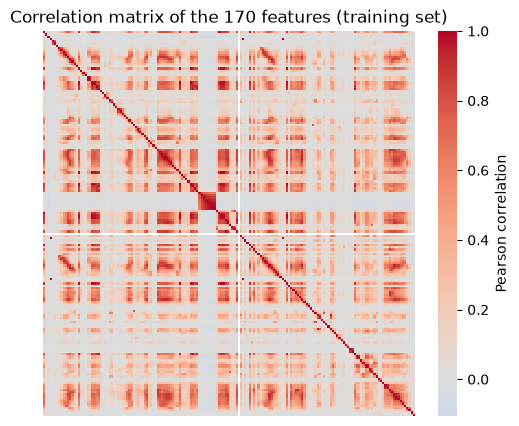

In [5]:
corr = Xtr.corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=False, yticklabels=False,
            cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation matrix of the 170 features (training set)")
plt.savefig("q1_corr.png", dpi=120, bbox_inches="tight"); plt.show()

#### (iv) Make scatter plots and box plots
$\lfloor\sqrt{170}\rfloor = 13$ features with the highest CV. Like Figure 4.1 (p. 129 of ISLR), the scatter plots are colored by
class and the box plots are split by class. The values are very skewed, so the axes use a log scale, $\log_{10}(1+x)$.

13 ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


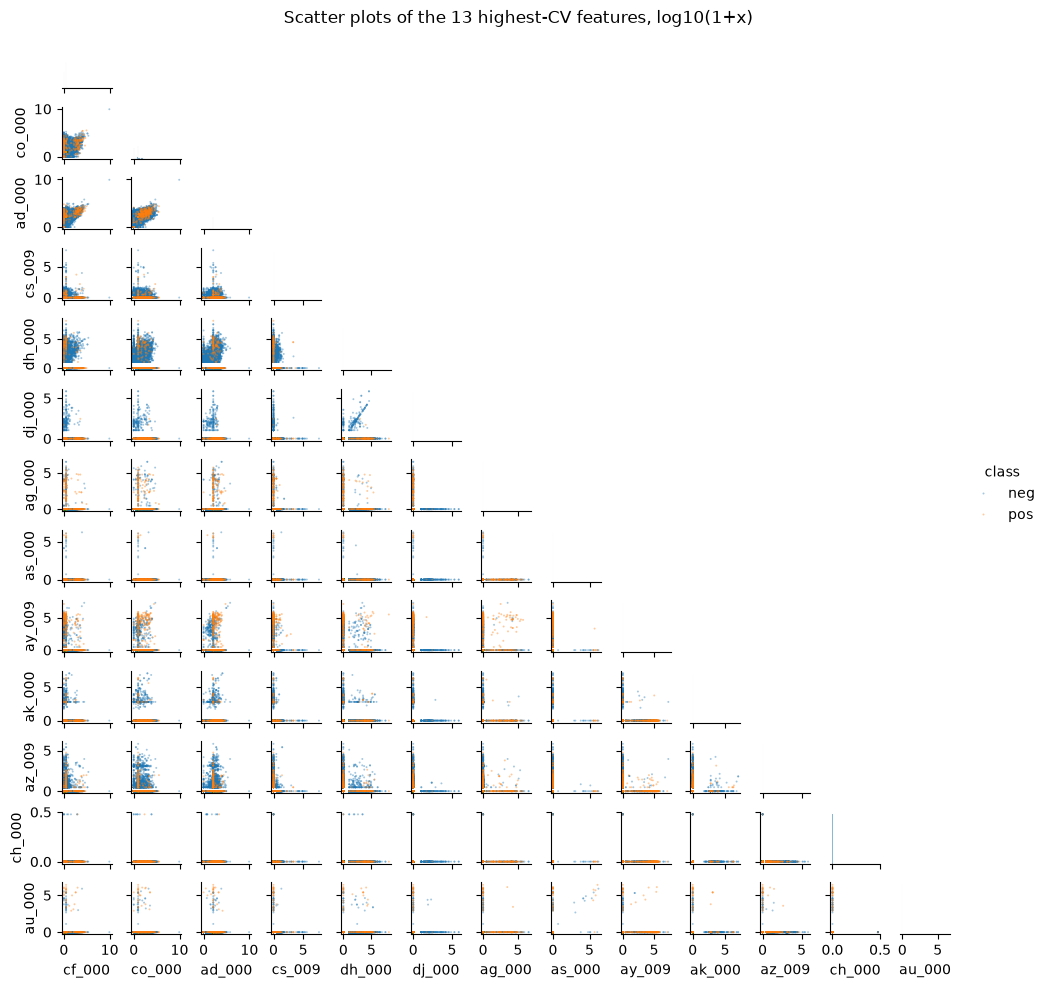

In [6]:
k = int(np.floor(np.sqrt(170)))
top = list(cv.index[:k])
print(k, top)

plot_df = np.log10(1 + Xtr[top].clip(lower=0))
plot_df["class"] = np.where(ytr == 1, "pos", "neg")
plot_df = pd.concat([plot_df[plot_df["class"] == "neg"], plot_df[plot_df["class"] == "pos"]])  # draw pos on top
g = sns.pairplot(plot_df, vars=top, hue="class", hue_order=["neg", "pos"], corner=True,
                 palette={"neg": "tab:blue", "pos": "tab:orange"},
                 plot_kws={"s": 2, "alpha": 0.4, "linewidth": 0}, diag_kind="hist", height=0.75)
g.figure.suptitle("Scatter plots of the 13 highest-CV features, log10(1+x)", y=1.01)
g.savefig("q1_scatter.png", dpi=80); plt.show()

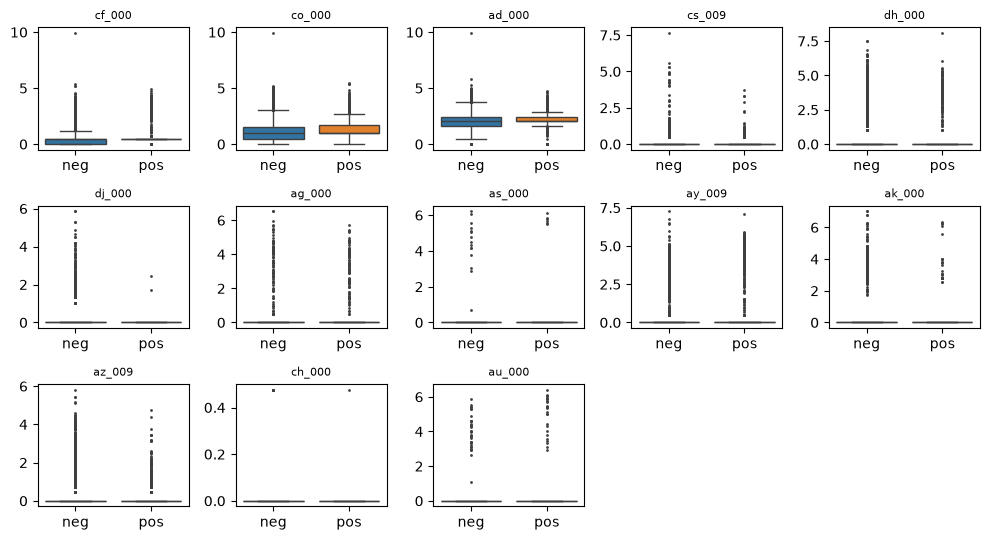

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(10, 5.5))
for ax, f in zip(axes.ravel(), top):
    sns.boxplot(x=plot_df["class"], y=plot_df[f], order=["neg", "pos"], ax=ax,
                palette={"neg": "tab:blue", "pos": "tab:orange"}, fliersize=1)
    ax.set_title(f, fontsize=8); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[k:]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("q1_box.png", dpi=110); plt.show()

**Can we draw conclusions about significance from the scatter plots alone?** No.
- A high CV here mostly comes from a few extreme values, not from a useful spread. `cf_000`, `co_000` and `ad_000` have
  CV around 245 because of one row with values near $8.6 \times 10^9$. Without the log scale every plot would be one dot cluster.
- Most of these features are 0 for almost all trucks (e.g. `dj_000`, `ch_000`, `as_000`), so the plots are mostly a pile at 0.
- Some features show a little difference between the classes. For example `ay_009`, `ag_000` and `az_009` are nonzero more
  often for the positive class, and `au_000` has many large positive values. But the two classes overlap a lot in every plot.
- The flat box for the positive class in `cf_000` is caused by the imputation: 65% of the positives are missing in this column
  (24% of the negatives), so many of them were filled with the same median. The missing pattern itself seems informative.
- A plot only shows one or two features at a time. It cannot tell us whether a feature still matters once the other 169 are in
  the model, and 1,000 orange points are easy to hide under 59,000 blue ones.

So the plots give some hints, but significance has to come from a model or a test, not from these pictures.

#### (v) Is this data set imbalanced?

In [8]:
counts = pd.DataFrame({"train": pd.Series(ytr).value_counts(), "test": pd.Series(yte).value_counts()})
counts.index = ["neg (0)", "pos (1)"]
print(counts)
print("positive share: train %.2f%%, test %.2f%%" % (100 * ytr.mean(), 100 * yte.mean()))

         train   test
neg (0)  59000  15625
pos (1)   1000    375
positive share: train 1.67%, test 2.34%


**Yes, it is very imbalanced.** The training set has 59,000 negatives and 1,000 positives (59 : 1, 1.67% positive), and the
test set has 15,625 negatives and 375 positives (2.34% positive). A model that always says "neg" would already have a 1.67%
training error, so the error rate alone is not a good measure here. I also look at the confusion matrix, AUC and the cost.

Helper functions used in (c)-(f). Besides the error rate and AUC I also print the challenge cost from the data description,
$10 \times FP + 500 \times FN$, because with only 1.7% positives the error rate alone hides the missed failures.

In [9]:
results = []

def evaluate(model, name):
    """Print confusion matrices and metrics for train and test, plot both ROC curves."""
    fig, ax = plt.subplots(figsize=(3.6, 3.2))
    for split, X, y in [("train", Xtr, ytr), ("test", Xte, yte)]:
        p = model.predict_proba(X)[:, 1]
        pred = (p >= 0.5).astype(int)
        cm = confusion_matrix(y, pred)
        tn, fp, fn, tp = cm.ravel()
        auc = roc_auc_score(y, p)
        row = {"model": name, "set": split, "error": (fp + fn) / len(y), "AUC": auc,
               "FP": fp, "FN": fn, "cost": 10 * fp + 500 * fn}
        results.append(row)
        print(f"--- {name}, {split} set: error = {row['error']:.4f}, AUC = {auc:.4f}, cost = {row['cost']}")
        print(pd.DataFrame(cm, index=["true neg", "true pos"], columns=["pred neg", "pred pos"]))
        fpr, tpr, _ = roc_curve(y, p)
        ax.plot(fpr, tpr, label=f"{split} (AUC = {auc:.4f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.set_title(f"ROC: {name}", fontsize=9); ax.legend(fontsize=7)
    fname = "roc_" + name.lower().replace(" ", "_").replace("(", "").replace(")", "") + ".png"
    plt.savefig(fname, dpi=110, bbox_inches="tight"); plt.show()

def test_error(name):
    return [r["error"] for r in results if r["model"] == name and r["set"] == "test"][0]

### (c) Train a random forest
No compensation for class imbalance. 300 trees, all other settings are the scikit-learn defaults.

fit time: 11 s
--- Random forest, train set: error = 0.0000, AUC = 1.0000, cost = 0
          pred neg  pred pos
true neg     59000         0
true pos         0      1000
--- Random forest, test set: error = 0.0076, AUC = 0.9942, cost = 52180
          pred neg  pred pos
true neg     15607        18
true pos       104       271


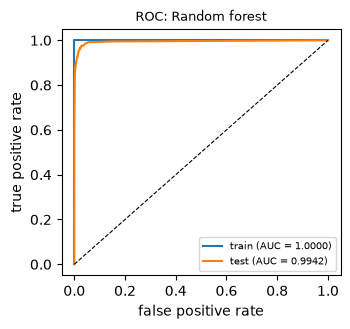

OOB error = 0.0058 | test error = 0.0076


In [10]:
t = time.time()
rf = RandomForestClassifier(n_estimators=300, oob_score=True, n_jobs=-1, random_state=RNG).fit(Xtr, ytr)
print("fit time: %.0f s" % (time.time() - t))
evaluate(rf, "Random forest")
print("OOB error = %.4f | test error = %.4f" % (1 - rf.oob_score_, test_error("Random forest")))

- **Training set:** error 0, AUC 1. The trees are grown until the leaves are pure, so the forest memorizes the training data.
  These numbers say nothing about how well it generalizes.
- **Test set:** error 0.76%, AUC 0.994. The error looks small, but 104 of the 375 failed trucks (28%) are missed, while only
  18 of 15,625 negatives are wrong. Almost all errors are on the minority class.
- **OOB error vs test error:** OOB error is 0.58% and the test error is 0.76%, so OOB is a good estimate but a bit lower.
  One reason is that the test set has more positives (2.34% vs 1.67%), and the positives are where the forest makes mistakes.

### (d) Research class imbalance in random forest
Ways to handle class imbalance in a random forest:
- **Class weights / cost-sensitive learning**: give the minority class a larger weight in the split criterion and in the leaf vote
  (`class_weight="balanced"` or `"balanced_subsample"` in scikit-learn).
- **Balanced random forest** (Chen, Liaw and Breiman, 2004): each tree is grown on a sample that has the same number of
  positives and negatives, by undersampling the majority class.
- **Resampling the training data** before fitting (oversampling such as SMOTE, or undersampling).
- **Changing the decision threshold** instead of using 0.5.

I use a **balanced random forest** (`BalancedRandomForestClassifier` from imbalanced-learn) with 300 trees.
Each tree is grown on all 1,000 positives and 1,000 randomly chosen negatives, then bootstrapped, so OOB error is still available.
For comparison I also fit a normal random forest with `class_weight="balanced_subsample"`.

fit time: 1 s
--- Balanced RF, train set: error = 0.0554, AUC = 0.9976, cost = 33260
          pred neg  pred pos
true neg     55674      3326
true pos         0      1000
--- Balanced RF, test set: error = 0.0529, AUC = 0.9924, cost = 11400
          pred neg  pred pos
true neg     14785       840
true pos         6       369


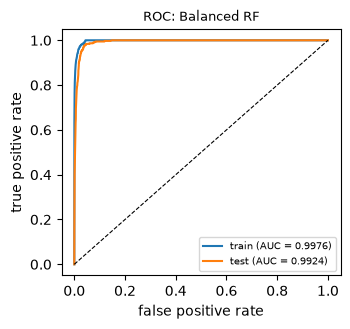

OOB error = 0.0514 | test error = 0.0529


In [11]:
t = time.time()
brf = BalancedRandomForestClassifier(n_estimators=300, sampling_strategy="auto", replacement=False,
                                     bootstrap=True, oob_score=True, n_jobs=-1,
                                     random_state=RNG).fit(Xtr, ytr)
print("fit time: %.0f s" % (time.time() - t))
evaluate(brf, "Balanced RF")
print("OOB error = %.4f | test error = %.4f" % (1 - brf.oob_score_, test_error("Balanced RF")))

--- Weighted RF, train set: error = 0.0000, AUC = 1.0000, cost = 0
          pred neg  pred pos
true neg     59000         0
true pos         0      1000
--- Weighted RF, test set: error = 0.0110, AUC = 0.9931, cost = 81140
          pred neg  pred pos
true neg     15611        14
true pos       162       213


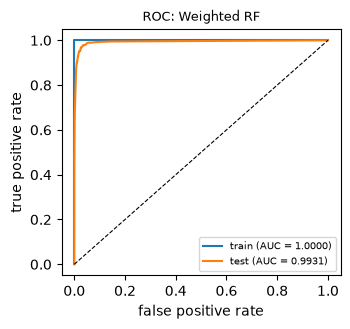

OOB error = 0.0076 | test error = 0.0110


In [12]:
rf_w = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", oob_score=True,
                              n_jobs=-1, random_state=RNG).fit(Xtr, ytr)
evaluate(rf_w, "Weighted RF")
print("OOB error = %.4f | test error = %.4f" % (1 - rf_w.oob_score_, test_error("Weighted RF")))

In [13]:
cols = ["model", "set", "error", "AUC", "FP", "FN", "cost"]
print(pd.DataFrame(results)[cols].round(4).to_string(index=False))

        model   set  error    AUC   FP  FN  cost
Random forest train 0.0000 1.0000    0   0     0
Random forest  test 0.0076 0.9942   18 104 52180
  Balanced RF train 0.0554 0.9976 3326   0 33260
  Balanced RF  test 0.0529 0.9924  840   6 11400
  Weighted RF train 0.0000 1.0000    0   0     0
  Weighted RF  test 0.0110 0.9931   14 162 81140


**Comparison with (c):**
- The balanced RF misses only **6** of the 375 failed trucks (104 in (c)), but it flags **840** good trucks (18 in (c)).
  So the test error goes up from 0.76% to 5.29%, while the challenge cost drops from 52,180 to 11,400.
- The test AUC hardly changes (0.992 vs 0.994). The ranking of the trucks is about the same. Balancing mainly moves the
  decision boundary toward the minority class.
- The OOB error (5.14%) is again close to the test error (5.29%). The training error is no longer 0, because each tree only
  sees 1,000 of the 59,000 negatives.
- `class_weight="balanced_subsample"` does not help here (162 missed positives). With fully grown trees the leaves are pure,
  so the weights barely change the predictions. Undersampling has a much bigger effect.

Which model is "better" depends on the goal. If we only count errors, (c) wins. If a missed failure is much more expensive than
an extra check, as in the data description, the balanced RF is much better.

### (e) XGBoost and Model Trees
XGBoost does not fit a logistic regression inside each node, so I use the closest version it offers:
gradient boosted trees with the logistic loss (`binary:logistic`) and an L1 penalty $\alpha$ (`reg_alpha`) on the leaf weights.
$\alpha$ is chosen by **5-fold stratified CV** (lowest CV log-loss). The same CV also gives the CV error of the chosen model,
which I compare with the test error. No compensation for class imbalance.

In [14]:
def make_xgb():
    return XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4, tree_method="hist",
                         eval_metric="logloss", n_jobs=-1, random_state=RNG)

skf = StratifiedKFold(5, shuffle=True, random_state=RNG)
alphas = [0, 0.01, 0.1, 1, 10, 100]
scoring = {"logloss": "neg_log_loss", "acc": "accuracy", "auc": "roc_auc"}

def cv_table(gs, prefix):
    r = gs.cv_results_
    return pd.DataFrame({"alpha": r[f"param_{prefix}reg_alpha"], "CV log-loss": -r["mean_test_logloss"],
                         "CV error": 1 - r["mean_test_acc"], "CV AUC": r["mean_test_auc"]})

t = time.time()
gs_xgb = GridSearchCV(make_xgb(), {"reg_alpha": alphas}, scoring=scoring, refit="logloss", cv=skf).fit(Xtr, ytr)
print("CV time: %.0f s" % (time.time() - t))
tab_e = cv_table(gs_xgb, "")
print(tab_e.round(5).to_string(index=False))
print("best alpha:", gs_xgb.best_params_["reg_alpha"])

CV time: 29 s
 alpha  CV log-loss  CV error  CV AUC
  0.00      0.01913   0.00568 0.98753
  0.01      0.01889   0.00537 0.98847
  0.10      0.01887   0.00550 0.98844
  1.00      0.01877   0.00558 0.98941
 10.00      0.02084   0.00722 0.98956
100.00      0.03278   0.01112 0.98220
best alpha: 1


--- XGBoost, train set: error = 0.0004, AUC = 0.9999, cost = 11000
          pred neg  pred pos
true neg     59000         0
true pos        22       978
--- XGBoost, test set: error = 0.0063, AUC = 0.9957, cost = 41680
          pred neg  pred pos
true neg     15607        18
true pos        83       292


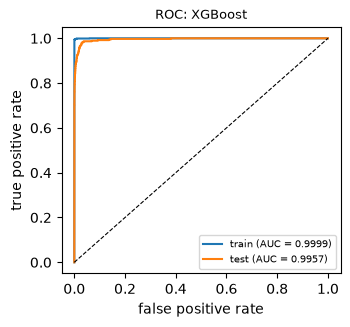

5-fold CV error = 0.0056 | test error = 0.0063


In [15]:
xgb = gs_xgb.best_estimator_
evaluate(xgb, "XGBoost")
cv_err_e = tab_e.loc[gs_xgb.best_index_, "CV error"]
print("5-fold CV error = %.4f | test error = %.4f" % (cv_err_e, test_error("XGBoost")))

- **Choice of $\alpha$:** $\alpha = 1$ has the lowest CV log-loss. Values from 0 to 1 are very close; $\alpha = 10$ and $100$
  are clearly worse, because the leaf weights are shrunk too much.
- **CV error vs test error:** the 5-fold CV error is 0.56% and the test error is 0.63%. They are close; the test error is a bit
  higher, probably for the same reason as in (c): the test set has a higher share of positives.
- **Train vs test:** training error 0.04% (22 missed positives) and AUC 0.9999; test AUC 0.996.
- Compared with the random forest in (c), XGBoost has a lower test error (0.63% vs 0.76%), a higher AUC (0.996 vs 0.994) and
  misses fewer failed trucks (83 vs 104), with the same 18 false positives. It still misses 22% of the positives.

### (f) Use SMOTE to pre-process your data
SMOTE is applied to the **whole** training set (no downsampling). It creates new positives on the line between a positive and one
of its 5 nearest positive neighbors, until both classes have 59,000 rows.

**Right way to cross-validate:** SMOTE must be done inside each fold, only on the training part of the fold. The validation fold
keeps its real class ratio and contains no synthetic points. I do this with an imbalanced-learn `Pipeline` (SMOTE + XGBoost)
inside `GridSearchCV`. The **wrong way** is to run SMOTE on the full training set first and then cross-validate: synthetic points
made from the same positives end up in both the training and validation folds, and the validation folds are balanced, so the CV
error does not represent the real data. I show both.

In [16]:
pipe = ImbPipeline([("smote", SMOTE(random_state=RNG)), ("xgb", make_xgb())])
t = time.time()
gs_sm = GridSearchCV(pipe, {"xgb__reg_alpha": alphas}, scoring=scoring, refit="logloss", cv=skf).fit(Xtr, ytr)
print("CV time: %.0f s" % (time.time() - t))
tab_f = cv_table(gs_sm, "xgb__")
print(tab_f.round(5).to_string(index=False))
print("best alpha:", gs_sm.best_params_["xgb__reg_alpha"])

CV time: 51 s
 alpha  CV log-loss  CV error  CV AUC
  0.00      0.02354   0.00750 0.98675
  0.01      0.02327   0.00732 0.98638
  0.10      0.02348   0.00748 0.98648
  1.00      0.02358   0.00760 0.98627
 10.00      0.02501   0.00832 0.98582
100.00      0.05327   0.01913 0.98422
best alpha: 0.01


after SMOTE: (118000, 170) | positives: 59000 | negatives: 59000
--- XGBoost SMOTE, train set: error = 0.0018, AUC = 0.9997, cost = 19700
          pred neg  pred pos
true neg     58930        70
true pos        38       962


--- XGBoost SMOTE, test set: error = 0.0110, AUC = 0.9929, cost = 26260
          pred neg  pred pos
true neg     15499       126
true pos        50       325


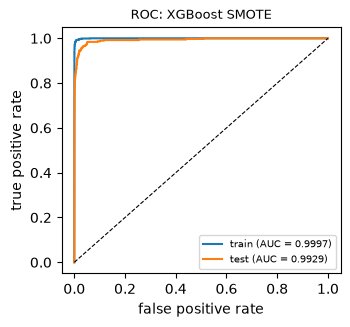

5-fold CV error (right way) = 0.0073 | test error = 0.0110


In [17]:
xgb_sm = gs_sm.best_estimator_          # refit on the full training set with SMOTE; SMOTE is skipped at predict time
X_sm, y_sm = SMOTE(random_state=RNG).fit_resample(Xtr, ytr)
print("after SMOTE:", X_sm.shape, "| positives:", y_sm.sum(), "| negatives:", (y_sm == 0).sum())
evaluate(xgb_sm, "XGBoost SMOTE")
cv_err_f = tab_f.loc[gs_sm.best_index_, "CV error"]
print("5-fold CV error (right way) = %.4f | test error = %.4f" % (cv_err_f, test_error("XGBoost SMOTE")))

In [18]:
wrong = cross_validate(make_xgb().set_params(reg_alpha=gs_sm.best_params_["xgb__reg_alpha"]),
                       X_sm, y_sm, cv=skf, scoring={"acc": "accuracy", "auc": "roc_auc"})
print("wrong way (SMOTE before CV): CV error = %.4f, CV AUC = %.4f"
      % (1 - wrong["test_acc"].mean(), wrong["test_auc"].mean()))

wrong way (SMOTE before CV): CV error = 0.0032, CV AUC = 0.9999


In [19]:
summary = pd.DataFrame(results)
summary = summary[summary["set"] == "test"][["model", "error", "AUC", "FP", "FN", "cost"]]
print("Test set comparison")
print(summary.round(4).to_string(index=False))

Test set comparison
        model  error    AUC  FP  FN  cost
Random forest 0.0076 0.9942  18 104 52180
  Balanced RF 0.0529 0.9924 840   6 11400
  Weighted RF 0.0110 0.9931  14 162 81140
      XGBoost 0.0063 0.9957  18  83 41680
XGBoost SMOTE 0.0110 0.9929 126  50 26260


**Right vs wrong cross-validation:**
- Wrong way (SMOTE before CV): CV error 0.32% and CV AUC 0.9999. This is far too optimistic; the real test error is 1.10%.
- Right way (SMOTE inside each fold): CV error 0.73%. It is much closer to the test error, though still a bit lower.

**SMOTE vs no compensation (e), on the test set:**

| | test error | AUC | missed positives (FN) | false alarms (FP) | cost |
|---|---|---|---|---|---|
| XGBoost (e) | 0.63% | 0.9957 | 83 | 18 | 41,680 |
| XGBoost + SMOTE (f) | 1.10% | 0.9929 | 50 | 126 | 26,260 |

With SMOTE the model catches 33 more failed trucks, but it makes 108 more false alarms. The error rate and AUC are slightly
worse, while the cost is lower because a missed failure costs 50 times more than a false alarm. Like in (d), compensating for the
imbalance mostly trades false negatives for false positives. In this run the balanced random forest from (d) still has the
lowest cost (11,400).

## 2. ISLR 6.6.3
We minimize $\sum_{i=1}^n \big(y_i - \beta_0 - \sum_{j} \beta_j x_{ij}\big)^2$ subject to $\sum_j |\beta_j| \le s$
(the lasso). When $s = 0$ all slopes are 0. As $s$ grows the constraint gets looser, and once $s$ is large enough
the solution is just least squares. So increasing $s$ means a more flexible model.

**(a) Training RSS: (iv) steadily decreases.** A larger $s$ allows every solution that was allowed before, so the
training RSS can only go down, until it reaches the least squares RSS.

**(b) Test RSS: (ii) decreases at first, then increases (U shape).** At first the model gains useful flexibility and the
bias drops faster than the variance grows. After some point it starts to overfit and the test RSS goes up again.

**(c) Variance: (iii) steadily increases.** At $s = 0$ the model is a constant and has almost no variance. As $s$ grows the
coefficients depend more on the particular training data.

**(d) Squared bias: (iv) steadily decreases.** A more flexible model can get closer to the true relationship.

**(e) Irreducible error: (v) remains constant.** It is $\mathrm{Var}(\epsilon)$, which does not depend on the model.

## 3. ISLR 6.6.5
Setup: $n = p = 2$, $x_{11} = x_{12}$, $x_{21} = x_{22}$, $x_{11} + x_{21} = 0$, $y_1 + y_2 = 0$, so $\hat\beta_0 = 0$.
To make the algebra short, write $x_{11} = x_{12} = x$, $x_{21} = x_{22} = -x$, $y_1 = y$, $y_2 = -y$.

**(a) Ridge optimization problem**

$$\min_{\beta_1, \beta_2}\; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(\beta_1^2 + \beta_2^2)$$

**(b) The ridge estimates satisfy $\hat\beta_1 = \hat\beta_2$**

Because $x_{i1} = x_{i2}$, the RSS only depends on $\beta_1 + \beta_2$:
$\text{RSS} = (y - (\beta_1+\beta_2)x)^2 + (-y + (\beta_1+\beta_2)x)^2 = 2\,(y - (\beta_1+\beta_2)x)^2$.
Setting the partial derivatives of the ridge objective to 0:

$$\frac{\partial}{\partial \beta_1}: \; -4x\,(y - (\beta_1+\beta_2)x) + 2\lambda\beta_1 = 0, \qquad
\frac{\partial}{\partial \beta_2}: \; -4x\,(y - (\beta_1+\beta_2)x) + 2\lambda\beta_2 = 0$$

The first terms are the same, so subtracting gives $2\lambda(\beta_1 - \beta_2) = 0$. Since $\lambda > 0$,
$\hat\beta_1 = \hat\beta_2$. (The objective is strictly convex for $\lambda > 0$, so this solution is unique:
$\hat\beta_1 = \hat\beta_2 = \dfrac{2xy}{4x^2 + \lambda}$.)

**(c) Lasso optimization problem**

$$\min_{\beta_1, \beta_2}\; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(|\beta_1| + |\beta_2|)$$

**(d) The lasso coefficients are not unique**

Let $t = \beta_1 + \beta_2$. The RSS is $2(y - tx)^2$, which depends only on $t$. For the penalty,
$|\beta_1| + |\beta_2| \ge |\beta_1 + \beta_2| = |t|$, with equality exactly when $\beta_1$ and $\beta_2$ have the same sign
(or one is 0). So for any fixed $t$ the smallest objective is $2(y - tx)^2 + \lambda|t|$, and every pair with
$\beta_1 + \beta_2 = t$ and the same sign reaches it.

Let $\hat t$ minimize $2(y - tx)^2 + \lambda|t|$. If $\hat t \neq 0$, say $\hat t > 0$, then every point on the segment
$$\hat\beta_1 + \hat\beta_2 = \hat t, \quad \hat\beta_1 \ge 0, \; \hat\beta_2 \ge 0$$
is a solution (and the same with $\le 0$ if $\hat t < 0$). There are infinitely many solutions, so they are not unique.
Geometrically, the RSS contours are lines parallel to $\beta_1 + \beta_2 = t$, and one of them touches the lasso diamond
along a whole edge, not at a single corner.

## 4. ISLR 8.4.5
The 10 bootstrap estimates of $P(\text{Red} \mid X)$ are 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75.

- **Majority vote:** 6 of the 10 estimates are above 0.5, so 6 trees vote Red and 4 vote Green. The final class is **Red**.
- **Average probability:** the mean is $4.5 / 10 = 0.45 < 0.5$, so the final class is **Green**.

The two approaches give different answers here.

In [20]:
p = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
print("votes for Red:", (p > 0.5).sum(), "of", len(p), "-> majority vote:", "Red" if (p > 0.5).sum() > len(p) / 2 else "Green")
print("average probability: %.3f -> average approach:" % p.mean(), "Red" if p.mean() > 0.5 else "Green")

votes for Red: 6 of 10 -> majority vote: Red
average probability: 0.450 -> average approach: Green


## 5. ISLR 9.7.3
Seven observations with $p = 2$:

| Obs | $X_1$ | $X_2$ | $Y$ |
|---|---|---|---|
| 1 | 3 | 4 | Red |
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 4 | 1 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |
| 7 | 4 | 1 | Blue |

**(a)** The sketch is the first plot below.

**(b)** The closest pairs across the two classes are obs 2 (2,2) with obs 5 (2,1), and obs 3 (4,4) with obs 6 (4,3).
Both pairs are 1 apart vertically, so the maximal margin hyperplane goes halfway between them:
it passes through (2, 1.5) and (4, 3.5), which is the line $X_2 = X_1 - 0.5$.

**(c)** Written as $\beta_0 + \beta_1 X_1 + \beta_2 X_2 = 0$: $\;0.5 - X_1 + X_2 = 0$, so $\beta_0 = 0.5$, $\beta_1 = -1$,
$\beta_2 = 1$. Classify to **Red if $0.5 - X_1 + X_2 > 0$**, and to **Blue otherwise**.

**(d)** The margin is the distance from a support vector to the hyperplane:
$\dfrac{|0.5 - 2 + 2|}{\sqrt{1^2 + 1^2}} = \dfrac{0.5}{\sqrt 2} = \dfrac{\sqrt 2}{4} \approx 0.354$.
The dashed lines in the second plot are $X_2 = X_1$ and $X_2 = X_1 - 1$.

**(e)** The support vectors are obs 2 (2,2), obs 3 (4,4), obs 5 (2,1) and obs 6 (4,3).

**(f)** Obs 7 (4,1) is not a support vector and is far from the margin, so a slight movement of it does not change the
maximal margin hyperplane.

**(g)** A separating hyperplane that is not optimal: $0.2 - X_1 + X_2 = 0$. It still separates the two classes, but it is
closer to the red points: its distance to obs 2 and obs 3 is only $0.2/\sqrt 2 \approx 0.14$, compared with 0.354 for the maximal margin hyperplane.

**(h)** If we add a **Red** observation at (4, 2), the classes cannot be separated: (4, 2) lies on the segment between the blue
points (4, 1) and (4, 3), so any line with both of those points on the blue side also has (4, 2) on the blue side.

The code below draws the plots and checks (b)-(e) and (h) with a linear SVM with a very large cost (close to a hard margin).

SVM hyperplane: 0.50 + -1.00*X1 + 1.00*X2 = 0
(sklearn puts Blue/Red in alphabetical order, so the sign may be flipped)
support vectors: [[2, 1], [4, 3], [2, 2], [4, 4]]
margin = 0.3537 (sqrt(2)/4 = 0.3536)


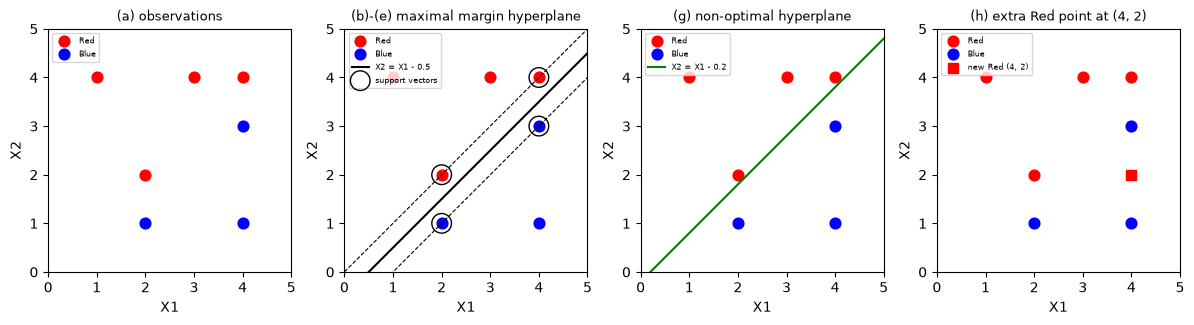

(h) training accuracy of a hard-margin linear SVM with the new point: 0.625
(g) 0.2 - X1 + X2 separates the data: True


In [21]:
X93 = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
y93 = np.array(["Red"] * 4 + ["Blue"] * 3)
colors = {"Red": "red", "Blue": "blue"}

svm = SVC(kernel="linear", C=1e6).fit(X93, y93)
w, b = svm.coef_[0], svm.intercept_[0]
scale = -1 / w[0]                       # rescale so that the X1 coefficient is -1, like in (c)
print("SVM hyperplane: %.2f + %.2f*X1 + %.2f*X2 = 0" % (b * scale, w[0] * scale, w[1] * scale))
print("(sklearn puts Blue/Red in alphabetical order, so the sign may be flipped)")
print("support vectors:", svm.support_vectors_.astype(int).tolist())
print("margin = %.4f (sqrt(2)/4 = %.4f)" % (1 / np.linalg.norm(w), np.sqrt(2) / 4))

xs = np.linspace(0, 5, 50)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
titles = ["(a) observations", "(b)-(e) maximal margin hyperplane", "(g) non-optimal hyperplane", "(h) extra Red point at (4, 2)"]
for ax, title in zip(axes, titles):
    for lab in ["Red", "Blue"]:
        ax.scatter(*X93[y93 == lab].T, c=colors[lab], s=60, label=lab)
    ax.set_xlim(0, 5); ax.set_ylim(0, 5); ax.set_aspect("equal"); ax.set_title(title, fontsize=9)
    ax.set_xlabel("X1"); ax.set_ylabel("X2")
axes[1].plot(xs, xs - 0.5, "k-", label="X2 = X1 - 0.5")
axes[1].plot(xs, xs, "k--", lw=0.8); axes[1].plot(xs, xs - 1, "k--", lw=0.8)
sv = svm.support_vectors_
axes[1].scatter(sv[:, 0], sv[:, 1], s=200, facecolors="none", edgecolors="k", label="support vectors")
axes[2].plot(xs, xs - 0.2, "g-", label="X2 = X1 - 0.2")
axes[3].scatter([4], [2], c="red", s=60, marker="s", label="new Red (4, 2)")
for ax in axes:
    ax.legend(loc="upper left", fontsize=6)
plt.tight_layout(); plt.savefig("q5_svm.png", dpi=110); plt.show()

X_h = np.vstack([X93, [4, 2]]); y_h = np.append(y93, "Red")
svm_h = SVC(kernel="linear", C=1e6).fit(X_h, y_h)
print("(h) training accuracy of a hard-margin linear SVM with the new point: %.3f" % svm_h.score(X_h, y_h))
g_ok = np.sign(0.2 - X93[:, 0] + X93[:, 1])
print("(g) 0.2 - X1 + X2 separates the data:", bool(np.all((g_ok > 0) == (y93 == "Red"))))